# Просмотр эффективности новых baseline-ов с улучшенным протоколом

### Импорты

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import time

import metrics
import baselines
import importlib
importlib.reload(metrics)
importlib.reload(baselines)

from metrics import build_eval_targets, build_context, evaluate_model
from baselines import (
    popularity_baseline,
    recent_popularity_baseline,
    last_item_baseline,
    pure_last_item_baseline,
    item_knn_baseline,
)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

PROC = Path('../data/processed')
RESULTS = Path('../results')
RESULTS.mkdir(exist_ok=True)

### Загрузка и подготовка данных

In [2]:
train = pd.read_parquet(PROC / 'train.parquet')
val   = pd.read_parquet(PROC / 'val.parquet')
test  = pd.read_parquet(PROC / 'test.parquet')

# Таргеты и контексты
val_targets  = build_eval_targets(val)
test_targets = build_eval_targets(test)

val_context  = build_context(train)
test_context = build_context(train, val)

print(f"Val targets:  {len(val_targets):,}  |  Test targets:  {len(test_targets):,}")
print(f"Val context:  {len(val_context):,}  |  Test context:  {len(test_context):,}")

Val targets:  176,224  |  Test targets:  186,690
Val context:  727,645  |  Test context:  727,645


### Оценивание всех baseline-ов на test

In [3]:
K_VALUES = (10, 50, 100)

# Словарь: имя → predict_fn
baseline_fns = {
    'Popularity':        popularity_baseline(train, top_n=200),
    'Recent-Popularity': recent_popularity_baseline(train, window_days=14, top_n=200),
    'Last-Item+FB':      last_item_baseline(train, top_n=200),
    'Pure Last-Item':    pure_last_item_baseline(train),
    'Item-kNN':          item_knn_baseline(train, top_k_similar=50, top_n=200),
}

results = {}
for name, fn in baseline_fns.items():
    print(f"\n=== {name} ===")
    t0 = time.time()
    m = evaluate_model(fn, test_targets, test_context, k_values=K_VALUES, verbose=False)
    dt = time.time() - t0
    results[name] = m
    print(f"  время: {dt:.1f} сек")
    for k, v in m.items():
        print(f"    {k:>12s}: {v:.4f}")


=== Popularity ===
  время: 3.8 сек
       Recall@10: 0.1643
         NDCG@10: 0.0901
          MAP@10: 0.0670
       Recall@50: 0.2807
         NDCG@50: 0.1150
          MAP@50: 0.0719
      Recall@100: 0.3490
        NDCG@100: 0.1261
         MAP@100: 0.0729

=== Recent-Popularity ===
  время: 11.0 сек
       Recall@10: 0.1601
         NDCG@10: 0.0846
          MAP@10: 0.0614
       Recall@50: 0.2622
         NDCG@50: 0.1066
          MAP@50: 0.0659
      Recall@100: 0.3325
        NDCG@100: 0.1180
         MAP@100: 0.0669

=== Last-Item+FB ===
  время: 5.2 сек
       Recall@10: 0.1614
         NDCG@10: 0.0720
          MAP@10: 0.0443
       Recall@50: 0.2807
         NDCG@50: 0.0975
          MAP@50: 0.0493
      Recall@100: 0.3482
        NDCG@100: 0.1084
         MAP@100: 0.0503

=== Pure Last-Item ===
  время: 0.9 сек
       Recall@10: 0.0000
         NDCG@10: 0.0000
          MAP@10: 0.0000
       Recall@50: 0.0000
         NDCG@50: 0.0000
          MAP@50: 0.0000
      Recall@

### Сводная таблица

In [4]:
results_df = pd.DataFrame(results).round(4)
results_df.index.name = 'metric'
print(results_df.to_string())

results_df.to_csv(RESULTS / 'baselines_v2_metrics.csv')
print(f"\nСохранено: {RESULTS / 'baselines_v2_metrics.csv'}")

            Popularity  Recent-Popularity  Last-Item+FB  Pure Last-Item  Item-kNN
metric                                                                           
Recall@10       0.1643             0.1601        0.1614             0.0    0.1842
NDCG@10         0.0901             0.0846        0.0720             0.0    0.1091
MAP@10          0.0670             0.0614        0.0443             0.0    0.0859
Recall@50       0.2807             0.2622        0.2807             0.0    0.3402
NDCG@50         0.1150             0.1066        0.0975             0.0    0.1429
MAP@50          0.0719             0.0659        0.0493             0.0    0.0929
Recall@100      0.3490             0.3325        0.3482             0.0    0.4298
NDCG@100        0.1261             0.1180        0.1084             0.0    0.1575
MAP@100         0.0729             0.0669        0.0503             0.0    0.0942

Сохранено: ..\results\baselines_v2_metrics.csv


### Визуализация

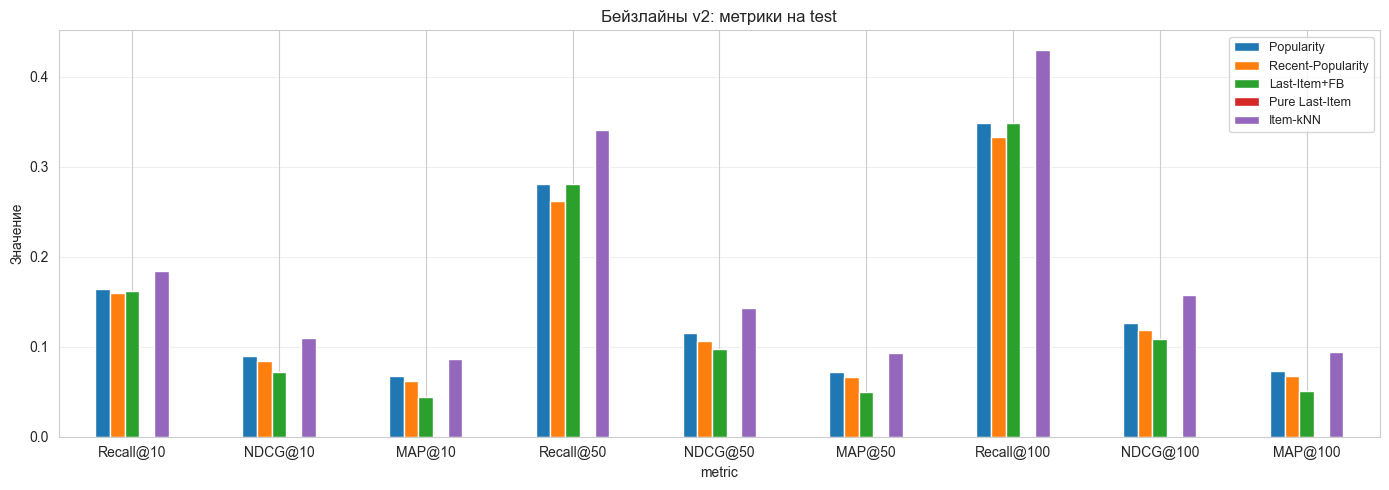

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
results_df.plot(kind='bar', ax=ax, rot=0)
ax.set_title('Бейзлайны v2: метрики на test')
ax.set_ylabel('Значение')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS / 'baselines_v2_metrics.png', dpi=100)
plt.show()

### Сохранение таргетов и контекста

In [6]:
val_targets.to_parquet(PROC / 'val_targets.parquet')
test_targets.to_parquet(PROC / 'test_targets.parquet')
print("Таргеты сохранены")

Таргеты сохранены
